# Chapter 1 Ekman

This code reproduces most of the plots in chapter 1

In [30]:
# First element in vector x must be 1.
# Length of w and x must be n+1 for neuron with n inputs.
def compute_output(w, x):
    z = 0.0    
    #print (f"w: {w}, x: {x}",len(w), len(x))
    for i in range(len(w)):
        z += x[i] * w[i] 
        # Compute sum of weighted inputs
        #print(f"i: {i}, x[i]: {x[i]}, w[i]: {w[i]}, z: {z}")
    if z < 0: # Apply sign function
        return -1    
    else:
        return 1


In [42]:
compute_output([0.9, -0.6, -0.5], [1.0, -1.0, -1.0])

1

In [44]:
for x1 in [ 1]:
    for x2 in [-1, 1]:
        for x3 in [-1, 1]:
            output = compute_output([0.9, -0.6, -0.5], [ x1, x2,x3])
            print(f"x1: {x1}, x2: {x2}, x3: {x3} => output: {output}")

x1: 1, x2: -1, x3: -1 => output: 1
x1: 1, x2: -1, x3: 1 => output: 1
x1: 1, x2: 1, x3: -1 => output: 1
x1: 1, x2: 1, x3: 1 => output: -1


In [45]:
import random
def show_learning(w):
    print('w0 =', '%5.2f' % w[0], ', w1 =', '%5.2f' % w[1],   ', w2 =', '%5.2f' % w[2])
# Define variables needed to control training process.
random.seed(9)  # To make repeatable
LEARNING_RATE = 0.1
index_list = [0, 1, 2, 3] # Used to randomize order


# Define training examples.
# 
x_train = [(1.0, -1.0, -1.0), (1.0, -1.0, 1.0),    (1.0, 1.0, -1.0), (1.0, 1.0, 1.0)] # Inputs
y_train = [1.0, 1.0, 1.0, -1.0] # Output (ground truth)
# Define perceptron weights.
w = [0.2, -0.6, 0.25] # Initialize to some "random" numbers
# Print initial weights.
show_learning(w)




w0 =  0.20 , w1 = -0.60 , w2 =  0.25


In [46]:
w = [0.2, -0.6, 0.25] 
# Perceptron training loop.
all_correct = False
while not all_correct:
    all_correct = True
    random.shuffle(index_list) # Randomize order
    for i in index_list:
        x = x_train[i]
        y = y_train[i]
        p_out = compute_output(w, x) # Perceptron function
        #print(i, x, 'desired:', y, 'perceptron output:', p_out)
        if y != p_out: # Update weights when wrong
            for j in range(0, len(w)):
                w[j] += (y * LEARNING_RATE * x[j])
            all_correct = False
            show_learning(w) # Show updated weights
show_learning(w)

w0 =  0.30 , w1 = -0.50 , w2 =  0.15
w0 =  0.40 , w1 = -0.40 , w2 =  0.05
w0 =  0.50 , w1 = -0.30 , w2 = -0.05
w0 =  0.40 , w1 = -0.40 , w2 = -0.15
w0 =  0.40 , w1 = -0.40 , w2 = -0.15


In [47]:
compute_output(w, [1.0, -2.0, -2.0])

1

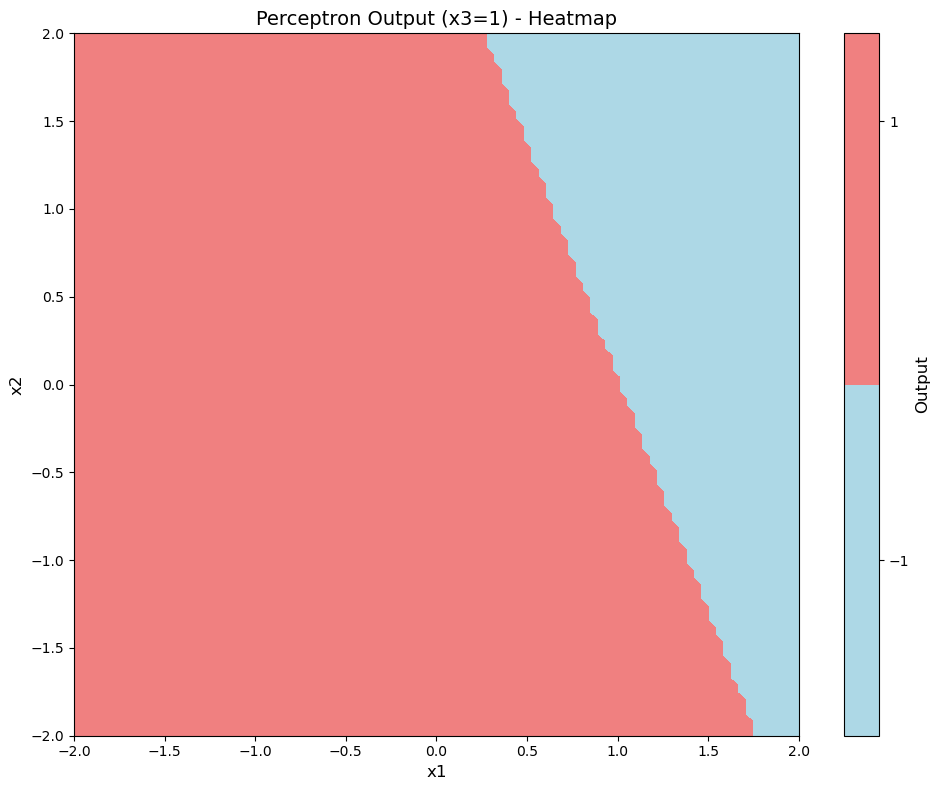

Trained weights: w0=0.40, w1=-0.40, w2=-0.15


In [49]:
import numpy as np
import matplotlib.pyplot as plt

w= [0.40 , -0.40 , -0.15]
# Create a grid of x1 and x2 values
x1_vals = np.linspace(-2, 2, 99)
x2_vals = np.linspace(-2, 2, 99)
X1, X2 = np.meshgrid(x1_vals, x2_vals)

# Compute perceptron output for each (x1, x2) pair
# Note: x3 is fixed to 1 (the bias term)
output = np.zeros_like(X1)
for i in range(len(x1_vals)):
    for j in range(len(x2_vals)):
        x1, x2 = X1[i, j], X2[i, j]
        output[i, j] = compute_output(w, [1.0, x1, x2])
# Create heatmap
fig, ax = plt.subplots(figsize=(10, 8))

heatmap = ax.contourf(X1, X2, output, levels=[-1.5, -0.5, 1.5], colors=['lightblue', 'lightcoral'])

# Add contour lines
#contours = ax.contour(X1, X2, output, levels=[-0.5, 0.5], colors='black', linewidths=2)

# Labels and title
ax.set_xlabel('x1', fontsize=12)
ax.set_ylabel('x2', fontsize=12)
ax.set_title('Perceptron Output (x3=1) - Heatmap', fontsize=14)

# Add colorbar
cbar = plt.colorbar(heatmap, ax=ax, ticks=[-1, 1])
cbar.set_label('Output', fontsize=12)

plt.tight_layout()
plt.show()

print(f"Trained weights: w0={w[0]:.2f}, w1={w[1]:.2f}, w2={w[2]:.2f}")

In [50]:
import matplotlib.pyplot as plt
import random
# Define variables needed for plotting.
color_list = ['r-', 'm-', 'y-', 'c-', 'b-', 'g-']
def show_learning(w,x_train,y_train):
    global color_index
    print('w0 =', '%5.2f' % w[0], ', w1 =', '%5.2f' % w[1],', w2 =', '%5.2f' % w[2])
    if color_index == 0:
        #plt.plot([1.0], [1.0], 'b_', markersize=12)
        #plt.plot([-1.0, 1.0, -1.0], [1.0, -1.0, -1.0],'r+', markersize=12)

        for i in range(len(y_train)):
            x= x_train[i]
            if y_train[i]<0.0:
                plt.plot([x[1]], [x[2]], 'b_', markersize=12)
            else:
                plt.plot([x[1]], [x[2]],'r+', markersize=12)
        plt.axis([-2, 2, -2, 2])
        plt.xlabel('x1')
        plt.ylabel('x2')
    x = [-2.0, 2.0]
    if abs(w[2]) < 1e-5:
        y = [-w[1]/(1e-5)*(-2.0)+(-w[0]/(1e-5)),-w[1]/(1e-5)*(2.0)+(-w[0]/(1e-5))]
    else:
        y = [-w[1]/w[2]*(-2.0)+(-w[0]/w[2]),-w[1]/w[2]*(2.0)+(-w[0]/w[2])]
    plt.plot(x, y, color_list[color_index])
    if color_index < (len(color_list) - 1):
        color_index += 1
        # Define variables needed to control training process.



w0 =  0.20 , w1 = -0.60 , w2 =  0.25


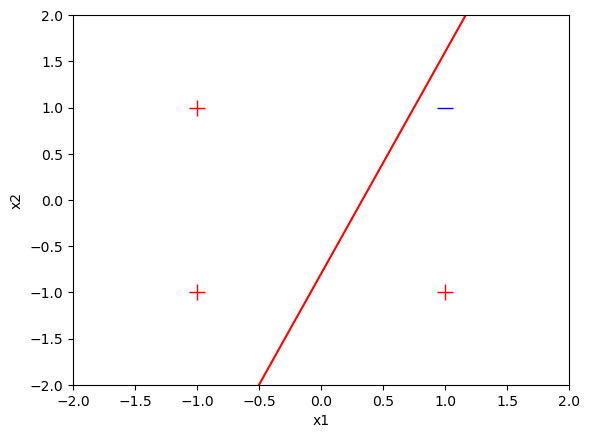

In [51]:
color_index=    0
random.seed(7) # To make repeatable
LEARNING_RATE = 0.1
index_list = [0, 1, 2, 3] # Used to randomize order


#  Define training examples.
x_train = [(1.0, -1.0, -1.0), (1.0, -1.0, 1.0),(1.0, 1.0, -1.0), (1.0, 1.0, 1.0)] # Inputs
y_train = [1.0, 1.0, 1.0, -1.0] # Output (ground truth)
# Define perceptron weights.
w = [0.2, -0.6, 0.25] # Initialize to some "random" numbers

# Print initial weights.
# 
show_learning(w,x_train,y_train)


w0 =  0.30 , w1 = -0.50 , w2 =  0.15
w0 =  0.40 , w1 = -0.40 , w2 =  0.05
w0 =  0.30 , w1 = -0.50 , w2 = -0.05
w0 =  0.40 , w1 = -0.40 , w2 = -0.15
w0 =  0.40 , w1 = -0.40 , w2 = -0.15

GIF saved as 'perceptron_training.gif' with 5 frames


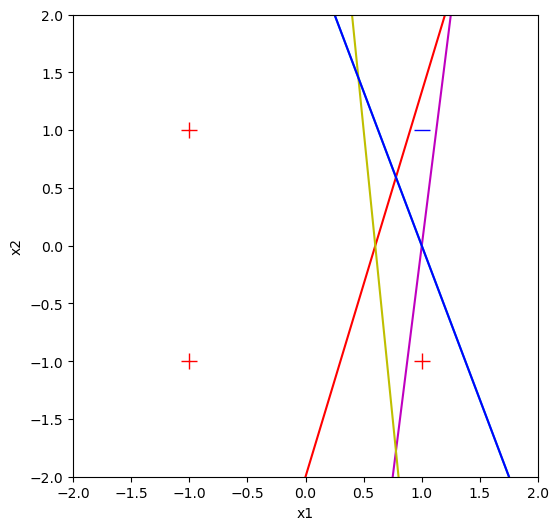

In [52]:
import io
import random
from PIL import Image

w = [0.2, -0.6, 0.25] 
color_index = 0
random.seed(7) # To make repeatable
LEARNING_RATE = 0.1
index_list = [0, 1, 2, 3] # Used to randomize order

# List to store frames for GIF
frames = []

def show_learning_gif(w, x_train, y_train, frames, is_first=False):
    """Modified show_learning that captures frames for GIF"""
    global color_index
    print('w0 =', '%5.2f' % w[0], ', w1 =', '%5.2f' % w[1],', w2 =', '%5.2f' % w[2])
    if is_first:
        for i in range(len(y_train)):
            x = x_train[i]
            if y_train[i] < 0.0:
                plt.plot([x[1]], [x[2]], 'b_', markersize=12)
            else:
                plt.plot([x[1]], [x[2]], 'r+', markersize=12)
        plt.axis([-2, 2, -2, 2])
        plt.xlabel('x1')
        plt.ylabel('x2')
    
    x = [-2.0, 2.0]
    if abs(w[2]) < 1e-5:
        y = [-w[1]/(1e-5)*(-2.0)+(-w[0]/(1e-5)), -w[1]/(1e-5)*(2.0)+(-w[0]/(1e-5))]
    else:
        y = [-w[1]/w[2]*(-2.0)+(-w[0]/w[2]), -w[1]/w[2]*(2.0)+(-w[0]/w[2])]
    plt.plot(x, y, color_list[color_index])
    if color_index < (len(color_list) - 1):
        color_index += 1
    
    # Capture frame
    buf = io.BytesIO()
    plt.savefig(buf, format='png', dpi=100, bbox_inches='tight')
    buf.seek(0)
    frames.append(Image.open(buf).copy())
    buf.close()

# Create figure once and keep it throughout training
fig = plt.figure(figsize=(6, 6))

# Perceptron training loop (runs once until convergence)
all_correct = False
first_update = True
while not all_correct:
    all_correct = True
    random.shuffle(index_list) # Randomize order
    for i in index_list:
        x = x_train[i]
        y = y_train[i]
        p_out = compute_output(w, x) # Perceptron function
        if y != p_out: # Update weights when wrong
            for j in range(0, len(w)):
                w[j] += (y * LEARNING_RATE * x[j])
            all_correct = False
            show_learning_gif(w, x_train, y_train, frames, is_first=first_update)
            first_update = False

# Final frame
show_learning_gif(w, x_train, y_train, frames, is_first=first_update)

# Save as GIF
if frames:
    frames[0].save('perceptron_training.gif', save_all=True, append_images=frames[1:], 
                   duration=500, loop=1)
    print(f"\nGIF saved as 'perceptron_training.gif' with {len(frames)} frames")

# Display final image in notebook
plt.show()
plt.close()


w0 =  0.20 , w1 = -0.60 , w2 =  0.25


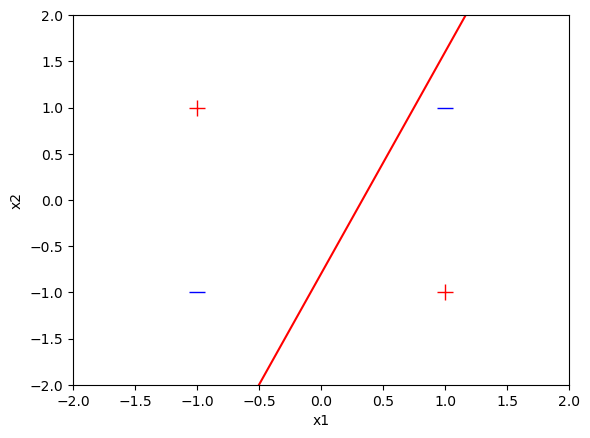

In [40]:
# XOR example
color_index=    0
random.seed(7) # To make repeatable
LEARNING_RATE = 0.1
index_list = [0, 1, 2, 3] # Used to randomize order
x_train = [(1.0, 1.0, 1.0), (1.0, -1.0, 1.0),(1.0, 1.0, -1.0), (1.0, -1.0, -1.0)] # Inputs
y_train = [-1.0, 1.0, 1.0, -1.0] # Output (ground truth)
#x_train = [(1.0, -1.0, -1.0), (1.0, -1.0, 1.0),(1.0, 1.0, -1.0), (1.0, 1.0, 1.0)] # Inputs
#y_train = [1.0, 1.0, 1.0, -1.0] # Output (ground truth)
w = [0.2, -0.6, 0.25] # Initialize to some "random" numbers

# Print initial weights.
# 
show_learning(w,x_train,y_train)


In [53]:
import io
from PIL import Image

w = [0.2, -0.6, 0.25] 
color_index = 0
random.seed(7) # To make repeatable
LEARNING_RATE = 0.1
index_list = [0, 1, 2, 3] # Used to randomize order
maxiterations = 20
iteration = 0

# List to store frames for GIF
frames = []

def capture_frame(frames):
    buf = io.BytesIO()
    plt.savefig(buf, format='png', dpi=100, bbox_inches='tight')
    buf.seek(0)
    frames.append(Image.open(buf).copy())
    buf.close()

# Create figure once and keep it throughout training
fig = plt.figure(figsize=(6, 6))

# Perceptron training loop.
all_correct = False
first_update = True
while not all_correct and iteration < maxiterations:
    iteration += 1
    all_correct = True
    random.shuffle(index_list) # Randomize order
    for i in index_list:
        x = x_train[i]
        y = y_train[i]
        p_out = compute_output(w, x) # Perceptron function
        if y != p_out: # Update weights when wrong
            for j in range(0, len(w)):
                w[j] += (y * LEARNING_RATE * x[j])
            all_correct = False
            if first_update:
                show_learning_gif(w, x_train, y_train)
                first_update = False
            else:
                # Reuse plot and add next decision line
                show_learning_gif(w, x_train, y_train)
            capture_frame(frames)

# Final frame
show_learning_gif(w, x_train, y_train)
capture_frame(frames)

# Save as GIF
if frames:
    frames[0].save('perceptron_training_limited.gif', save_all=True, append_images=frames[1:],
                   duration=500, loop=1)
    print(f"\nGIF saved as 'perceptron_training_limited.gif' with {len(frames)} frames")

# Display final image in notebook
plt.show()
plt.close()


TypeError: show_learning_gif() missing 1 required positional argument: 'frames'

<Figure size 600x600 with 0 Axes>

In [15]:
# Figure 1-9

In [17]:


# Two-layer neural network: 2 inputs -> 2 hidden nodes -> 1 output

# Delta (step) activation function
def delta(z):
    return np.where(z >= 0, 1, -1)

# Forward pass through network
def forward_pass(x1, x2, w1, b1, w2, b2):
    """
    x1, x2: inputs
    w1: weights from inputs to hidden layer (2x2 matrix)
    b1: bias for hidden layer (2 values)
    w2: weights from hidden to output (2 values)
    b2: bias for output (scalar)
    
    Returns: output, hidden activations, hidden z values
    """
    # Hidden layer
    z_hidden = np.array([w1[0,0]*x1 + w1[0,1]*x2 + b1[0],
                         w1[1,0]*x1 + w1[1,1]*x2 + b1[1]])
    p = delta(z_hidden)  # p0, p1
    
    # Output layer
    z_output = w2[0]*p[0] + w2[1]*p[1] + b2
    y2 = delta(z_output)
    
    return y2, p, z_hidden, z_output

# Training data
x_train = [(1.0, -1.0), (1.0, 1.0), (-1.0, -1.0), (-1.0, 1.0)]
y_train = [1.0, -1.0, -1.0, 1.0]  # XOR-like pattern



In [54]:
w1 = np.array([[-0.6, -0.5], [0.6, 0.6]])
b1 = np.array([0.9, 0.2])
w2 = np.array([0.6, 0.6])
b2 = -0.9

print (w1,b1,w2,b2)

print("\nNetwork predictions on training data:")
for x_sample, y_target in zip(x_train, y_train):
    x1, x2 = x_sample
    y2, _, _, _ = forward_pass(x1, x2, w1, b1, w2, b2)
    print(f"Input: ({x1:4.1f}, {x2:4.1f}) -> Target: {y_target:.1f}, Predicted: {y2:.3f}")


[[-0.6 -0.5]
 [ 0.6  0.6]] [0.9 0.2] [0.6 0.6] -0.9

Network predictions on training data:


ValueError: too many values to unpack (expected 2)

In [ ]:
# Debug: Let's see what's happening at each layer
print("Debugging network outputs:")
print(f"{'Input':<20} {'p0':<10} {'p1':<10} {'Output':<10} {'Target':<10}")
print("-" * 60)
for x_sample, y_target in zip(x_train, y_train):
    x1, x2 = x_sample
    y2, p, z_hidden, z_output = forward_pass(x1, x2, w1, b1, w2, b2)
    print(f"({x1:4.1f}, {x2:4.1f})      {p[0]:.4f}     {p[1]:.4f}     {y2:.4f}      {y_target:.1f}")


Debugging network outputs:
Input                p0         p1         Output     Target    
------------------------------------------------------------
( 1.0, -1.0)      1.0000     1.0000     1.0000      1.0
( 1.0,  1.0)      -1.0000     1.0000     -1.0000      -1.0
(-1.0, -1.0)      1.0000     -1.0000     -1.0000      -1.0
(-1.0,  1.0)      1.0000     1.0000     1.0000      1.0


In [19]:
# Linear algebra annotations...



# Column-vector style (conceptually); in NumPy 1D is fine for most ops
x = np.array([1.0, -1.0,  1.0])   # x0 is bias input = 1
w = np.array([0.9, -0.6, -0.5])   # w0 is bias weight

# Elementwise vector addition (requires same length)
a = np.array([1.0, 2.0, 3.0])
b = np.array([4.0, 5.0, 6.0])
print("a+b =", a + b)

# "Transpose" note:
# NumPy 1D transpose doesn't change shape; use reshape to make column/row vectors explicit
x_col = x.reshape(-1, 1)   # (n,1)
x_row = x.reshape(1, -1)   # (1,n)
print("x_col:", x_col, "x_row:", x_row)

print("x_col shape:", x_col.shape, "x_row shape:", x_row.shape)






a+b = [5. 7. 9.]
x_col: [[ 1.]
 [-1.]
 [ 1.]] x_row: [[ 1. -1.  1.]]
x_col shape: (3, 1) x_row shape: (1, 3)


In [20]:
#Dot product = weighted sum (perceptron z)
def perceptron_z(w, x):
    return np.dot(w, x)  # dot product

def sign01(z):
    # Book uses sign function: 1 if z >= 0 else -1
    return 1 if z >= 0 else -1

w = np.array([0.9, -0.6, -0.5])
x = np.array([1.0, 1.0, 1.0])  # bias + two inputs
z = perceptron_z(w, x)
y = sign01(z)

print("z =", z, "y =", y)


z = -0.19999999999999996 y = -1


In [21]:
# Description of dot product calculation
def dot_manual(u, v):
    if len(u) != len(v):
        raise ValueError("Vectors must have same length")
    s = 0.0
    for i in range(len(u)):
        s += u[i] * v[i]
    return s

print("manual dot:", dot_manual(w, x), "numpy dot:", np.dot(w, x))


manual dot: -0.19999999999999996 numpy dot: -0.19999999999999996


In [22]:
# Vectorized perceptron output computation

def compute_output_vector(w, x):
    z = np.dot(w, x)
    # np.sign returns 0 when z==0; we map 0 to +1 to match ">=0 -> 1"
    return 1 if z >= 0 else -1

tests = [
    (np.array([1.0, -1.0, -1.0])),
    (np.array([1.0, -1.0,  1.0])),
    (np.array([1.0,  1.0, -1.0])),
    (np.array([1.0,  1.0,  1.0])),
]
w = np.array([0.9, -0.6, -0.5])

for x in tests:
    print(x, "->", compute_output_vector(w, x))


[ 1. -1. -1.] -> 1
[ 1. -1.  1.] -> 1
[ 1.  1. -1.] -> 1
[1. 1. 1.] -> -1


In [23]:
# Matrix vector multiuplication example


# Two perceptrons (rows), each has bias + 2 inputs => 3 weights per neuron
W = np.array([
    [0.9, -0.6, -0.5],  # neuron 0 weights
    [0.2,  0.6,  0.6],  # neuron 1 weights
])

x = np.array([1.0, -1.0, 1.0])   # one input example (bias, x1, x2)

z = W @ x    # matrix-vector multiply
_triangle = (z >= 0).astype(int) * 2 - 1  # map True->1, False->-1

print("z:", z)
print("outputs:", _triangle)


z: [1.  0.2]
outputs: [1 1]


In [24]:
# Matrix Matrix multiplication example


# W: 2 neurons x 3 weights
W = np.array([
    [0.9, -0.6, -0.5],
    [0.2,  0.6,  0.6],
])

# X: 3 features (bias,x1,x2) x 4 examples (columns)
X = np.array([
    [ 1.0,  1.0,  1.0,  1.0],  # bias
    [-1.0, -1.0,  1.0,  1.0],  # x1
    [-1.0,  1.0, -1.0,  1.0],  # x2
])

Z = W @ X  # 2 x 4 weighted sums (matches the book’s worked example)
Y = np.where(Z >= 0, 1, -1)

print("Z=\n", Z)
print("Y=\n", Y)


Z=
 [[ 2.   1.   0.8 -0.2]
 [-1.   0.2  0.2  1.4]]
Y=
 [[ 1  1  1 -1]
 [-1  1  1  1]]


In [25]:
# Show that dot product and matrix multiplication are related

import numpy as np

a = np.array([1.0, 2.0, 3.0]).reshape(1, -1)  # (1,n)
b = np.array([4.0, 5.0, 6.0]).reshape(-1, 1)  # (n,1)

dot_as_matmul = (a @ b)[0, 0]
print("a·b via matmul:", dot_as_matmul)
print("a·b via dot:", np.dot(a.ravel(), b.ravel()))


a·b via matmul: 32.0
a·b via dot: 32.0


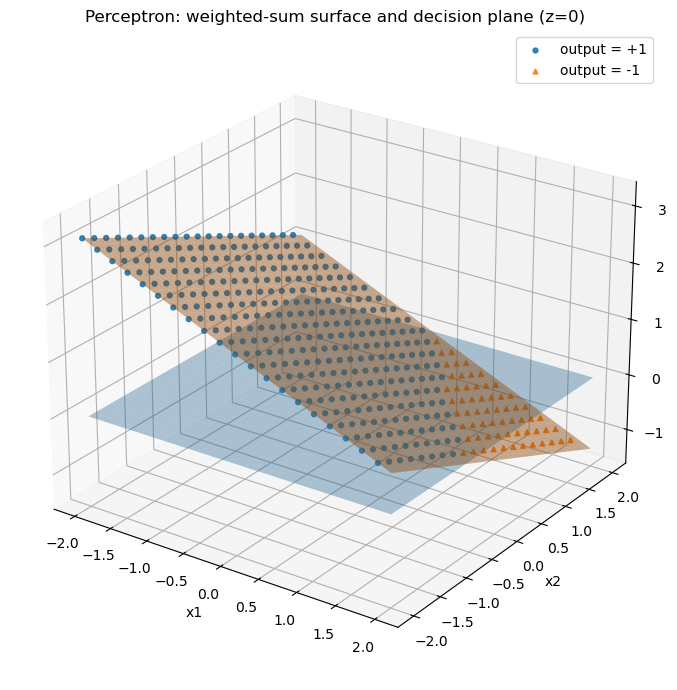

In [26]:

# --- Perceptron parameters (bias + two inputs) ---
w0, w1, w2 = 0.9, -0.6, -0.5   # change these to match your example

def z_value(x1, x2):
    return w0 + w1*x1 + w2*x2

def perceptron_output(x1, x2):
    z = z_value(x1, x2)
    return np.where(z >= 0, 1, -1)

# --- Grid over input space (x1, x2) ---
x1 = np.linspace(-2, 2, 120)
x2 = np.linspace(-2, 2, 120)
X1, X2 = np.meshgrid(x1, x2)

Z = z_value(X1, X2)                 # continuous weighted sum
Y = perceptron_output(X1, X2)       # discrete output (+1 / -1)

# --- Plot ---
fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(111, projection="3d")

# 1) Decision plane z=0 (where the perceptron flips class)
ax.plot_surface(
    X1, X2, np.zeros_like(Z),
    alpha=0.35, linewidth=0, antialiased=True
)

# 2) Plot the weighted-sum surface z(x1,x2)
ax.plot_surface(
    X1, X2, Z,
    alpha=0.45, linewidth=0, antialiased=True
)

# 3) Scatter points colored by perceptron output (to show regions clearly)
#    (subsample grid so it’s not too dense)
step = 6
Xs = X1[::step, ::step].ravel()
Ys = X2[::step, ::step].ravel()
Zs = Z[::step, ::step].ravel()
Out = perceptron_output(Xs, Ys)

ax.scatter(
    Xs[Out == 1],  Ys[Out == 1],  Zs[Out == 1],
    marker="o", s=12, alpha=0.9, label="output = +1"
)
ax.scatter(
    Xs[Out == -1], Ys[Out == -1], Zs[Out == -1],
    marker="^", s=12, alpha=0.9, label="output = -1"
)

# Labels and view
ax.set_title("Perceptron: weighted-sum surface and decision plane (z=0)")
ax.set_xlabel("x1")
ax.set_ylabel("x2")
ax.set_zlabel("z = w0 + w1*x1 + w2*x2")
ax.view_init(elev=25, azim=-55)

ax.legend()
plt.tight_layout()
plt.show()


Output with bias input: -1
Output without bias input: 1


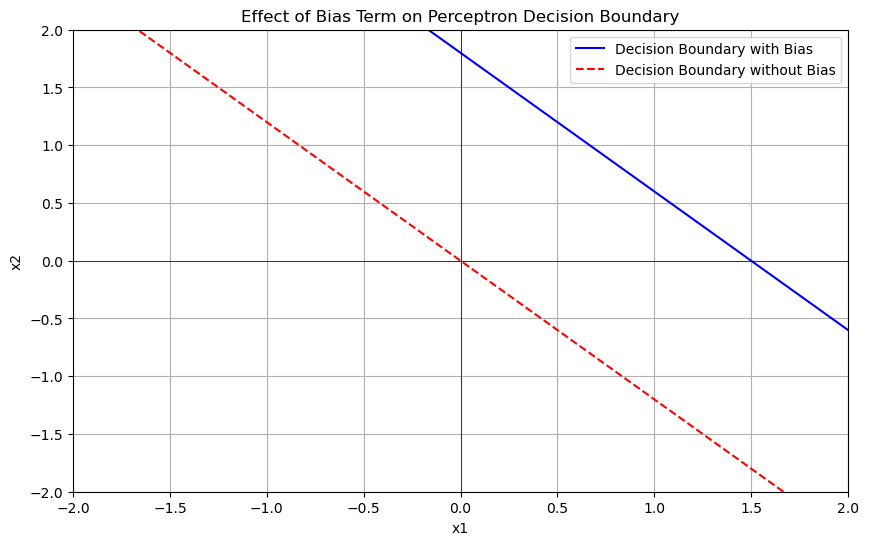

In [55]:
# Understanding the bias term in perceptrons
import numpy as np
def perceptron_output(w, x):
    z = np.dot(w, x)
    return 1 if z >= 0 else -1

# Example weights and inputs
w = np.array([0.9, -0.6, -0.5])
x_with_bias = np.array([1.0, 1.0, 1.0])   # with bias input
x_no_bias = np.array([1.0, 1.0, 0.0])    # without bias input
output_with_bias = perceptron_output(w, x_with_bias)
output_no_bias = perceptron_output(w, x_no_bias)
print("Output with bias input:", output_with_bias)
print("Output without bias input:", output_no_bias)
# Visualize decision boundary with and without bias
import matplotlib.pyplot as plt
x1 = np.linspace(-2, 2, 100)
# With bias: w0 + w1*x1 + w2*x2 = 0 => x2 = -(w0 + w1*x1)/w2
x2_with_bias = -(w[0] + w[1]*x1) / w[2]
# Without bias: w1*x1 + w2*x2 = 0 => x2 = -(w1*x1)/w2
x2_no_bias = -(w[1]*x1) / w[2]
plt.figure(figsize=(10, 6))
plt.plot(x1, x2_with_bias, label='Decision Boundary with Bias', color='blue')
plt.plot(x1, x2_no_bias, label='Decision Boundary without Bias', color='red', linestyle='--')
plt.axhline(0, color='black', linewidth=0.5)
plt.axvline(0, color='black', linewidth=0.5)
plt.xlim(-2, 2)
plt.ylim(-2, 2)
plt.xlabel('x1')
plt.ylabel('x2')
plt.title('Effect of Bias Term on Perceptron Decision Boundary')
plt.legend()
plt.grid()
plt.show()   

## Mini-exercises ( for students)

- Replace W and X with your own values and verify shapes.

- Make 3 neurons (W is 3×3) and 10 examples (X is 3×10). Compute Z = W@X.


- Implement matvec_manual(A, x) and matmul_manual(A, B) using nested loops, then compare to NumPy with np.allclose.
